<a href="https://colab.research.google.com/github/Pamodya-Wijesinghe/EN3160-Assignment-3-on-Neural-Networks/blob/main/230727P_EN3160_Assignment_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3160 Assignment 3: Neural Networks

**Name:** W. A. P. W. Wijesinghe

**Index Number:** 230727P

**GitHub Link:** https://github.com/Pamodya-Wijesinghe/EN3160-Assignment-3-on-Neural-Networks

This notebook contains:
1. A dense neural network with manual backpropagation on CIFAR-10.
2. A comparison of LeNet-5 and a small CNN on MNIST.
3. Transfer learning with ResNet18 on the hymenoptera dataset.

In [1]:
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision

SEED = 727

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

RESULTS_DIR = Path("/content/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Device: cuda
GPU: Tesla T4


## Question 1: Dense Network with Manual Backpropagation

The network uses CIFAR-10 images. Each image has three colour channels
and a size of 32 × 32 pixels.

The image is flattened into 3072 input values. These values pass through
a hidden layer with 100 neurons and sigmoid activation. The output layer
produces scores for the 10 classes.

Network structure:
3072 inputs → 100 sigmoid hidden neurons → 10 output scores

Softmax converts the output scores into class probabilities.
Cross-entropy measures the prediction error.

The gradients and parameter updates are calculated manually.

In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Use the same normalization as the assignment's starting code.
q1_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

q1_trainset = datasets.CIFAR10(
    root="/content/data",
    train=True,
    download=True,
    transform=q1_transform
)

q1_testset = datasets.CIFAR10(
    root="/content/data",
    train=False,
    download=True,
    transform=q1_transform
)

BATCH_SIZE = 50

q1_trainloader = DataLoader(
    q1_trainset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

q1_testloader = DataLoader(
    q1_testset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

classes = q1_trainset.classes

images, labels = next(iter(q1_trainloader))

print("Training images:", len(q1_trainset))
print("Test images:", len(q1_testset))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Classes:", classes)

100%|██████████| 170M/170M [57:04<00:00, 49.8kB/s]


Training images: 50000
Test images: 10000
Image batch shape: torch.Size([50, 3, 32, 32])
Label batch shape: torch.Size([50])
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


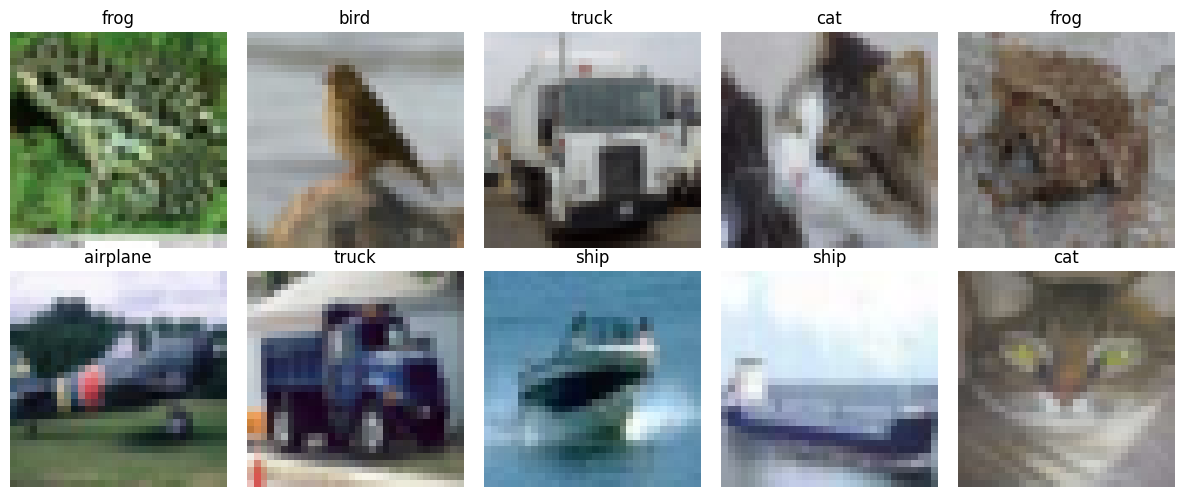

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    # Undo normalization for display.
    image = images[i] * 0.5 + 0.5

    ax.imshow(image.permute(1, 2, 0).numpy().clip(0, 1))
    ax.set_title(classes[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "q1_cifar10_samples.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [4]:
import math
import time

# Reset the seed so rerunning this cell starts from the same parameters.
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

D_IN = 3 * 32 * 32
HIDDEN = 100
N_CLASSES = 10

# Xavier-style initialization is suitable for the sigmoid hidden layer.
# These tensors do not track gradients.
W1 = (
    torch.randn(D_IN, HIDDEN, device=device)
    * math.sqrt(2.0 / (D_IN + HIDDEN))
)
b1 = torch.zeros(HIDDEN, device=device)

W2 = (
    torch.randn(HIDDEN, N_CLASSES, device=device)
    * math.sqrt(2.0 / (HIDDEN + N_CLASSES))
)
b2 = torch.zeros(N_CLASSES, device=device)

EPOCHS = 10
INITIAL_LR = 0.1
LR_DECAY = 0.9

q1_history = {
    "train_loss": [],
    "test_loss": [],
    "train_acc": [],
    "test_acc": []
}

print("W1:", W1.shape)
print("b1:", b1.shape)
print("W2:", W2.shape)
print("b2:", b2.shape)

parameter_count = sum(
    p.numel() for p in (W1, b1, W2, b2)
)

print("Total trainable parameters:", parameter_count)

W1: torch.Size([3072, 100])
b1: torch.Size([100])
W2: torch.Size([100, 10])
b2: torch.Size([10])
Total trainable parameters: 308310


In [5]:
def q1_forward(x):
    hidden = torch.sigmoid(x @ W1 + b1)
    logits = hidden @ W2 + b2
    return hidden, logits


def q1_log_probs(logits):
    # Stable log-softmax: avoids directly taking log of tiny probabilities.
    return logits - torch.logsumexp(
        logits, dim=1, keepdim=True
    )


@torch.no_grad()
def q1_evaluate(loader):
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        x = images.to(device).flatten(start_dim=1)
        y = labels.to(device)

        _, logits = q1_forward(x)
        log_probs = q1_log_probs(logits)

        rows = torch.arange(y.size(0), device=device)

        # Sum losses first, then divide by the full dataset size.
        total_loss += (-log_probs[rows, y]).sum().item()
        total_correct += (
            logits.argmax(dim=1) == y
        ).sum().item()
        total_samples += y.size(0)

    mean_loss = total_loss / total_samples
    accuracy = 100.0 * total_correct / total_samples

    return mean_loss, accuracy


# No shuffling is needed when measuring training-set performance.
q1_train_eval_loader = DataLoader(
    q1_trainset,
    batch_size=256,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

In [6]:
start_time = time.time()

with torch.no_grad():
    for epoch in range(EPOCHS):
        lr = INITIAL_LR * (LR_DECAY ** epoch)

        for images, labels in q1_trainloader:
            x = images.to(device).flatten(start_dim=1)
            y = labels.to(device)

            batch_n = y.size(0)
            rows = torch.arange(batch_n, device=device)

            # 1. Forward pass
            hidden, logits = q1_forward(x)
            log_probs = q1_log_probs(logits)

            # 2. Gradient of average cross-entropy with softmax
            d_logits = log_probs.exp()
            d_logits[rows, y] -= 1.0
            d_logits /= batch_n

            # 3. Output-layer gradients
            dW2 = hidden.T @ d_logits
            db2 = d_logits.sum(dim=0)

            # 4. Hidden-layer gradients
            # Calculate this before changing W2.
            d_hidden_pre = (
                (d_logits @ W2.T)
                * hidden
                * (1.0 - hidden)
            )

            dW1 = x.T @ d_hidden_pre
            db1 = d_hidden_pre.sum(dim=0)

            # 5. Manual gradient-descent updates
            W1 -= lr * dW1
            b1 -= lr * db1
            W2 -= lr * dW2
            b2 -= lr * db2

        # Evaluate the completed epoch.
        train_loss, train_acc = q1_evaluate(
            q1_train_eval_loader
        )
        test_loss, test_acc = q1_evaluate(q1_testloader)

        q1_history["train_loss"].append(train_loss)
        q1_history["test_loss"].append(test_loss)
        q1_history["train_acc"].append(train_acc)
        q1_history["test_acc"].append(test_acc)

        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"LR: {lr:.4f} | "
            f"Train loss: {train_loss:.4f} | "
            f"Test loss: {test_loss:.4f} | "
            f"Train accuracy: {train_acc:.2f}% | "
            f"Test accuracy: {test_acc:.2f}%"
        )

print(f"\nTraining time: {time.time() - start_time:.1f} seconds")

Epoch 01/10 | LR: 0.1000 | Train loss: 1.6899 | Test loss: 1.7044 | Train accuracy: 40.80% | Test accuracy: 40.43%
Epoch 02/10 | LR: 0.0900 | Train loss: 1.6232 | Test loss: 1.6578 | Train accuracy: 44.23% | Test accuracy: 42.75%
Epoch 03/10 | LR: 0.0810 | Train loss: 1.5641 | Test loss: 1.6182 | Train accuracy: 46.14% | Test accuracy: 43.71%
Epoch 04/10 | LR: 0.0729 | Train loss: 1.5246 | Test loss: 1.5915 | Train accuracy: 47.55% | Test accuracy: 44.47%
Epoch 05/10 | LR: 0.0656 | Train loss: 1.4868 | Test loss: 1.5662 | Train accuracy: 49.09% | Test accuracy: 45.67%
Epoch 06/10 | LR: 0.0590 | Train loss: 1.4548 | Test loss: 1.5497 | Train accuracy: 50.14% | Test accuracy: 46.84%
Epoch 07/10 | LR: 0.0531 | Train loss: 1.4290 | Test loss: 1.5349 | Train accuracy: 50.97% | Test accuracy: 46.90%
Epoch 08/10 | LR: 0.0478 | Train loss: 1.4096 | Test loss: 1.5307 | Train accuracy: 51.54% | Test accuracy: 47.11%
Epoch 09/10 | LR: 0.0430 | Train loss: 1.3822 | Test loss: 1.5159 | Train accura

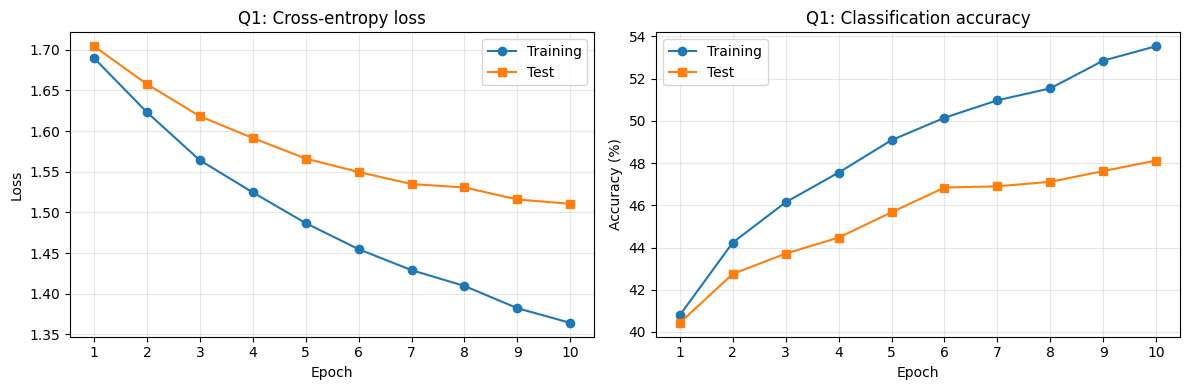

,epoch,train_loss,test_loss,train_acc,test_acc
0,1,1.6899,1.7044,40.798,40.43
1,2,1.6232,1.6578,44.234,42.75
2,3,1.5641,1.6182,46.144,43.71
3,4,1.5246,1.5915,47.548,44.47
4,5,1.4868,1.5662,49.086,45.67
5,6,1.4548,1.5497,50.144,46.84
6,7,1.4290,1.5349,50.972,46.90
7,8,1.4096,1.5307,51.538,47.11
8,9,1.3822,1.5159,52.852,47.62
9,10,1.3641,1.5105,53.536,48.12



Final training accuracy: 53.54%
Final test accuracy: 48.12%


In [7]:
import pandas as pd

epochs = np.arange(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    epochs, q1_history["train_loss"], "o-", label="Training"
)
axes[0].plot(
    epochs, q1_history["test_loss"], "s-", label="Test"
)
axes[0].set_title("Q1: Cross-entropy loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs, q1_history["train_acc"], "o-", label="Training"
)
axes[1].plot(
    epochs, q1_history["test_acc"], "s-", label="Test"
)
axes[1].set_title("Q1: Classification accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

for ax in axes:
    ax.set_xticks(epochs)

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "q1_training_curves.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

q1_results = pd.DataFrame({
    "epoch": epochs,
    **q1_history
})

q1_results.to_csv(
    RESULTS_DIR / "q1_metrics.csv",
    index=False
)

torch.save(
    {
        "W1": W1.cpu(),
        "b1": b1.cpu(),
        "W2": W2.cpu(),
        "b2": b2.cpu(),
        "history": q1_history,
        "seed": SEED,
        "initial_lr": INITIAL_LR,
        "lr_decay": LR_DECAY,
        "epochs": EPOCHS
    },
    RESULTS_DIR / "q1_manual_network.pt"
)

display(q1_results.round(4))

print(
    f"\nFinal training accuracy: "
    f"{q1_history['train_acc'][-1]:.2f}%"
)
print(
    f"Final test accuracy: "
    f"{q1_history['test_acc'][-1]:.2f}%"
)

In [8]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/q1_results",
    "zip",
    root_dir=RESULTS_DIR
)

files.download("/content/q1_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Discussion

After 10 epochs, the network achieved a training accuracy of 53.54%
and a test accuracy of 48.12%. Training loss decreased from 1.6899
to 1.3641, while test loss decreased from 1.7044 to 1.5105.
This shows that the network learned useful information from the images.

Training accuracy was 5.42 percentage points higher than test accuracy.
This suggests some overfitting. However, test loss continued to decrease
throughout training.

The network flattens each image into a vector, so it does not directly
use the spatial arrangement of nearby pixels as a CNN does. This limits
its ability to learn image patterns. The results were obtained using
100 sigmoid hidden neurons and manually calculated gradients.

## Question 2: Comparing LeNet-5 and a Small CNN

Two networks are trained on MNIST for 10 epochs:

1. A LeNet-5-style network with tanh activations and average pooling.
2. A small CNN with three convolutional layers, batch normalization,
   ReLU activations and dropout.

Both models use the same dataset split, preprocessing, batch size,
optimizer, learning rate and number of epochs.

Training and test loss and accuracy are recorded after each epoch.
A test-set confusion matrix is calculated for each model.

In [9]:
import torch.nn as nn

q2_transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

q2_trainset = datasets.MNIST(
    root="/content/data",
    train=True,
    download=True,
    transform=q2_transform
)

q2_testset = datasets.MNIST(
    root="/content/data",
    train=False,
    download=True,
    transform=q2_transform
)

Q2_BATCH_SIZE = 128
Q2_EPOCHS = 10
Q2_LR = 0.001


def make_q2_trainloader():
    # A fresh generator gives each model the same shuffle sequence.
    generator = torch.Generator().manual_seed(SEED)

    return DataLoader(
        q2_trainset,
        batch_size=Q2_BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=2,
        pin_memory=(device.type == "cuda")
    )


q2_train_eval_loader = DataLoader(
    q2_trainset,
    batch_size=256,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

q2_testloader = DataLoader(
    q2_testset,
    batch_size=256,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

sample_images, sample_labels = next(iter(q2_testloader))

print("Training images:", len(q2_trainset))
print("Test images:", len(q2_testset))
print("Image batch shape:", sample_images.shape)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 493kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.0MB/s]


Training images: 60000
Test images: 10000
Image batch shape: torch.Size([256, 1, 32, 32])


In [10]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),

            nn.Conv2d(6, 16, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),

            nn.Conv2d(16, 120, kernel_size=5),
            nn.Tanh()
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [11]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # 32 × 32 → 16 × 16
            nn.Conv2d(
                1, 32, kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 16 × 16 → 8 × 8
            nn.Conv2d(
                32, 64, kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 8 × 8 → 4 × 4
            nn.Conv2d(
                64, 128, kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [12]:
# Check output shapes before training.
dummy_input = torch.zeros(2, 1, 32, 32)

for model_class in (LeNet5, SmallCNN):
    model = model_class()
    model.eval()

    with torch.no_grad():
        output = model(dummy_input)

    parameter_count = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )

    print(model_class.__name__)
    print("Output shape:", output.shape)
    print("Trainable parameters:", parameter_count)
    print()

LeNet5
Output shape: torch.Size([2, 10])
Trainable parameters: 61706

SmallCNN
Output shape: torch.Size([2, 10])
Trainable parameters: 356458



In [13]:
@torch.no_grad()
def q2_evaluate(model, loader):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    criterion = nn.CrossEntropyLoss(reduction="sum")

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)

        total_loss += criterion(logits, labels).item()
        total_correct += (
            logits.argmax(dim=1) == labels
        ).sum().item()
        total_samples += labels.size(0)

    return (
        total_loss / total_samples,
        100.0 * total_correct / total_samples
    )

In [14]:
def q2_train(model_class):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = model_class().to(device)
    trainloader = make_q2_trainloader()

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=Q2_LR
    )

    history = {
        "train_loss": [],
        "test_loss": [],
        "train_acc": [],
        "test_acc": []
    }

    start_time = time.perf_counter()

    for epoch in range(Q2_EPOCHS):
        model.train()

        for images, labels in trainloader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

        train_loss, train_acc = q2_evaluate(
            model, q2_train_eval_loader
        )
        test_loss, test_acc = q2_evaluate(
            model, q2_testloader
        )

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)

        print(
            f"{model_class.__name__} | "
            f"Epoch {epoch + 1:02d}/{Q2_EPOCHS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Test loss: {test_loss:.4f} | "
            f"Train accuracy: {train_acc:.2f}% | "
            f"Test accuracy: {test_acc:.2f}%",
            flush=True
        )

    elapsed = time.perf_counter() - start_time
    print(f"Total training and evaluation time: {elapsed:.1f} s")

    return model, history, elapsed

In [15]:
lenet_model, lenet_history, lenet_time = q2_train(LeNet5)

LeNet5 | Epoch 01/10 | Train loss: 0.1195 | Test loss: 0.1170 | Train accuracy: 96.36% | Test accuracy: 96.36%
LeNet5 | Epoch 02/10 | Train loss: 0.0647 | Test loss: 0.0664 | Train accuracy: 98.01% | Test accuracy: 97.86%
LeNet5 | Epoch 03/10 | Train loss: 0.0450 | Test loss: 0.0484 | Train accuracy: 98.67% | Test accuracy: 98.36%
LeNet5 | Epoch 04/10 | Train loss: 0.0347 | Test loss: 0.0415 | Train accuracy: 98.97% | Test accuracy: 98.63%
LeNet5 | Epoch 05/10 | Train loss: 0.0283 | Test loss: 0.0401 | Train accuracy: 99.13% | Test accuracy: 98.69%
LeNet5 | Epoch 06/10 | Train loss: 0.0231 | Test loss: 0.0396 | Train accuracy: 99.32% | Test accuracy: 98.66%
LeNet5 | Epoch 07/10 | Train loss: 0.0182 | Test loss: 0.0395 | Train accuracy: 99.45% | Test accuracy: 98.79%
LeNet5 | Epoch 08/10 | Train loss: 0.0176 | Test loss: 0.0427 | Train accuracy: 99.45% | Test accuracy: 98.77%
LeNet5 | Epoch 09/10 | Train loss: 0.0116 | Test loss: 0.0375 | Train accuracy: 99.66% | Test accuracy: 98.91%
L

In [16]:
smallcnn_model, smallcnn_history, smallcnn_time = q2_train(
    SmallCNN
)

SmallCNN | Epoch 01/10 | Train loss: 0.0481 | Test loss: 0.0423 | Train accuracy: 98.50% | Test accuracy: 98.63%
SmallCNN | Epoch 02/10 | Train loss: 0.0640 | Test loss: 0.0682 | Train accuracy: 97.95% | Test accuracy: 98.06%
SmallCNN | Epoch 03/10 | Train loss: 0.0217 | Test loss: 0.0255 | Train accuracy: 99.29% | Test accuracy: 99.10%
SmallCNN | Epoch 04/10 | Train loss: 0.0276 | Test loss: 0.0354 | Train accuracy: 99.10% | Test accuracy: 99.00%
SmallCNN | Epoch 05/10 | Train loss: 0.0175 | Test loss: 0.0280 | Train accuracy: 99.42% | Test accuracy: 99.16%
SmallCNN | Epoch 06/10 | Train loss: 0.0125 | Test loss: 0.0231 | Train accuracy: 99.60% | Test accuracy: 99.29%
SmallCNN | Epoch 07/10 | Train loss: 0.0106 | Test loss: 0.0201 | Train accuracy: 99.66% | Test accuracy: 99.36%
SmallCNN | Epoch 08/10 | Train loss: 0.0142 | Test loss: 0.0315 | Train accuracy: 99.50% | Test accuracy: 99.12%
SmallCNN | Epoch 09/10 | Train loss: 0.0085 | Test loss: 0.0278 | Train accuracy: 99.72% | Test 

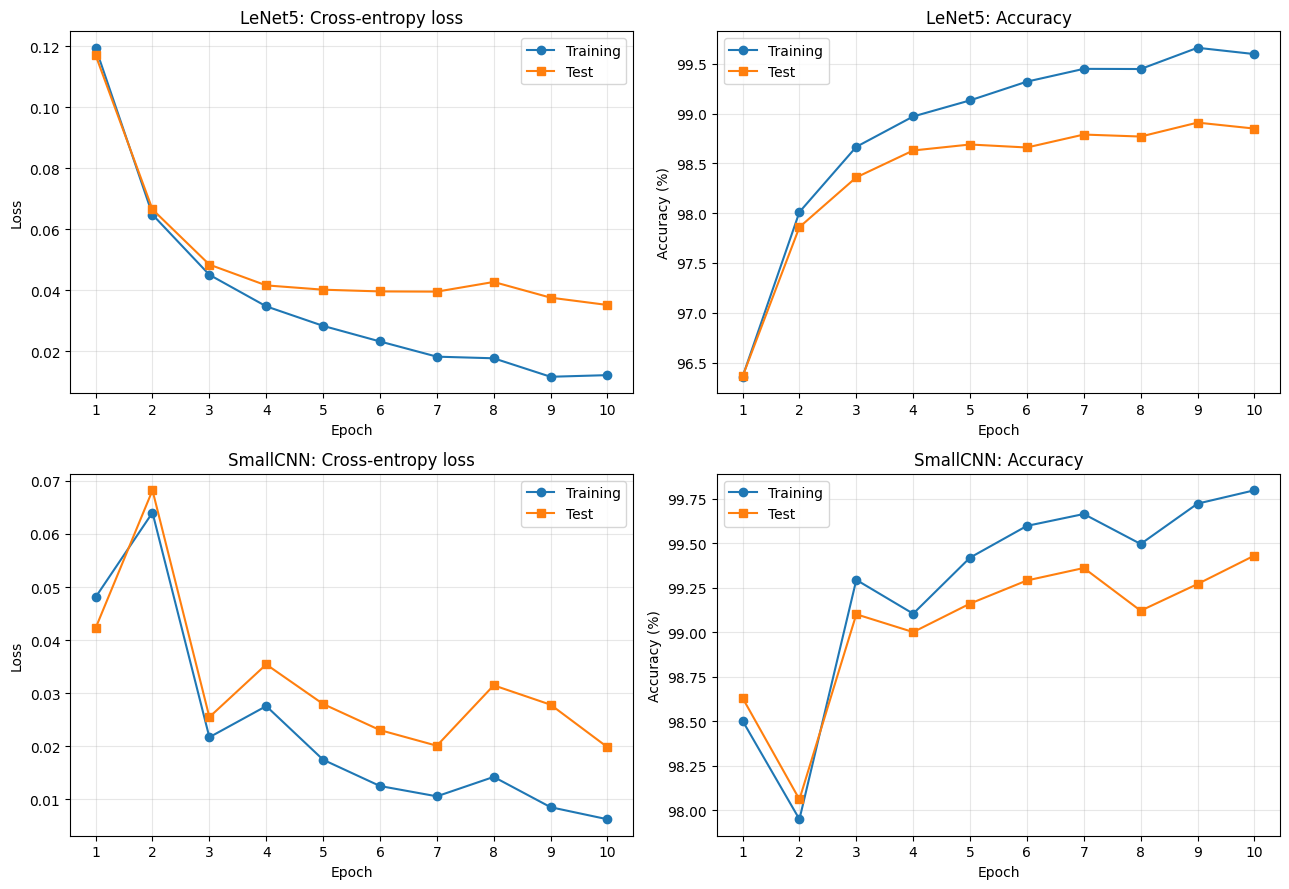

In [17]:
q2_runs = {
    "LeNet5": (lenet_model, lenet_history, lenet_time),
    "SmallCNN": (
        smallcnn_model, smallcnn_history, smallcnn_time
    )
}

q2_epochs = np.arange(1, Q2_EPOCHS + 1)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for row, (name, (_, history, _)) in enumerate(q2_runs.items()):
    axes[row, 0].plot(
        q2_epochs, history["train_loss"], "o-", label="Training"
    )
    axes[row, 0].plot(
        q2_epochs, history["test_loss"], "s-", label="Test"
    )
    axes[row, 0].set_title(f"{name}: Cross-entropy loss")
    axes[row, 0].set_ylabel("Loss")

    axes[row, 1].plot(
        q2_epochs, history["train_acc"], "o-", label="Training"
    )
    axes[row, 1].plot(
        q2_epochs, history["test_acc"], "s-", label="Test"
    )
    axes[row, 1].set_title(f"{name}: Accuracy")
    axes[row, 1].set_ylabel("Accuracy (%)")

    for ax in axes[row]:
        ax.set_xlabel("Epoch")
        ax.set_xticks(q2_epochs)
        ax.legend()
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "q2_training_curves.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

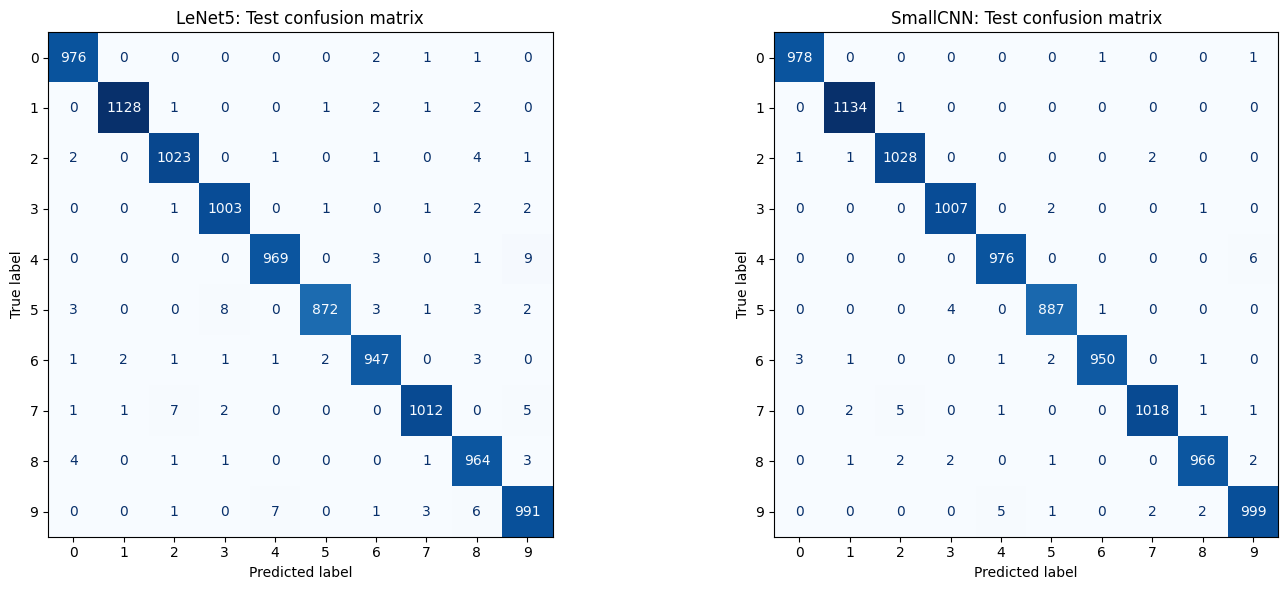

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


@torch.no_grad()
def q2_get_predictions(model, loader):
    model.eval()

    actual = []
    predicted = []

    for images, labels in loader:
        logits = model(images.to(device))

        actual.append(labels.cpu().numpy())
        predicted.append(logits.argmax(dim=1).cpu().numpy())

    return np.concatenate(actual), np.concatenate(predicted)


q2_confusion_matrices = {}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (name, (model, _, _)) in zip(axes, q2_runs.items()):
    actual, predicted = q2_get_predictions(
        model, q2_testloader
    )

    cm = confusion_matrix(
        actual, predicted, labels=np.arange(10)
    )
    q2_confusion_matrices[name] = cm

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=np.arange(10)
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(f"{name}: Test confusion matrix")

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "q2_confusion_matrices.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [19]:
q2_summary_rows = []

for name, (model, history, elapsed) in q2_runs.items():
    metrics = pd.DataFrame({
        "epoch": q2_epochs,
        **history
    })

    metrics.to_csv(
        RESULTS_DIR / f"q2_{name}_metrics.csv",
        index=False
    )

    pd.DataFrame(
        q2_confusion_matrices[name],
        index=pd.Index(range(10), name="Actual"),
        columns=pd.Index(range(10), name="Predicted")
    ).to_csv(
        RESULTS_DIR / f"q2_{name}_confusion_matrix.csv"
    )

    # Save CPU copies without moving the working model off the GPU.
    torch.save(
        {
            "model_state_dict": {
                key: value.detach().cpu()
                for key, value in model.state_dict().items()
            },
            "history": history,
            "seed": SEED,
            "epochs": Q2_EPOCHS,
            "batch_size": Q2_BATCH_SIZE,
            "learning_rate": Q2_LR,
            "optimizer": "Adam"
        },
        RESULTS_DIR / f"q2_{name}.pt"
    )

    q2_summary_rows.append({
        "Model": name,
        "Parameters": sum(
            p.numel() for p in model.parameters()
            if p.requires_grad
        ),
        "Train loss": history["train_loss"][-1],
        "Test loss": history["test_loss"][-1],
        "Train accuracy (%)": history["train_acc"][-1],
        "Test accuracy (%)": history["test_acc"][-1],
        "Train-test gap (pp)": (
            history["train_acc"][-1] - history["test_acc"][-1]
        ),
        "Training + evaluation time (s)": elapsed
    })

q2_summary = pd.DataFrame(q2_summary_rows)

q2_summary.to_csv(
    RESULTS_DIR / "q2_model_comparison.csv",
    index=False
)

display(q2_summary.round(4))

,Model,Parameters,Train loss,Test loss,Train accuracy (%),Test accuracy (%),Train-test gap (pp),Training + evaluation time (s)
0,LeNet5,61706,0.0121,0.0351,99.5983,98.85,0.7483,270.8268
1,SmallCNN,356458,0.0063,0.0198,99.7967,99.43,0.3667,272.3863


In [20]:
shutil.make_archive(
    "/content/assignment_results_q1_q2",
    "zip",
    root_dir=RESULTS_DIR
)

files.download("/content/assignment_results_q1_q2.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>